In [2]:
# ============================================
# AQI FORECASTER — Data Pipeline
# All Imports
# ============================================

import requests
import pandas as pd
import numpy as np
import os
import json
import time
from datetime import datetime, timedelta
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

# Paths setup
BASE_DIR = Path('../')
RAW_DIR  = BASE_DIR / 'data/raw'
PROC_DIR = BASE_DIR / 'data/processed'

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROC_DIR.mkdir(parents=True, exist_ok=True)

print("All imports successful!")
print(f"Pandas: {pd.__version__}, NumPy: {np.__version__}")

All imports successful!
Pandas: 3.0.6, NumPy: 2.4.6


In [7]:
# ============================================
#  WAQI API — Real Time Data
# ============================================

from dotenv import load_dotenv
load_dotenv('../.env', override=True)

WAQI_TOKEN = os.getenv('WAQI_TOKEN')
print(f"Token loaded: {WAQI_TOKEN[:8]}... (hidden)")

CITIES = ['Delhi', 'Mumbai', 'Berlin', 'Geneva', 'Los Angeles']

def fetch_waqi_data(cities):
    """Fetch real-time AQI from WAQI API — no login needed"""
    all_records = []

    for city in cities:
        url = f"https://api.waqi.info/feed/{city}/"
        params = {'token': WAQI_TOKEN}

        try:
            resp = requests.get(url, params=params, timeout=15)
            data = resp.json()

            if data['status'] == 'ok':
                d = data['data']
                iaqi = d.get('iaqi', {})

                record = {
                    'city':      city,
                    'aqi':       d.get('aqi', None),
                    'datetime':  d.get('time', {}).get('iso', ''),
                    'pm25':      iaqi.get('pm25', {}).get('v', None),
                    'pm10':      iaqi.get('pm10', {}).get('v', None),
                    'no2':       iaqi.get('no2',  {}).get('v', None),
                    'o3':        iaqi.get('o3',   {}).get('v', None),
                    'co':        iaqi.get('co',   {}).get('v', None),
                    'humidity':  iaqi.get('h',    {}).get('v', None),
                    'temperature': iaqi.get('t',  {}).get('v', None),
                    'wind':      iaqi.get('w',    {}).get('v', None),
                    'pressure':  iaqi.get('p',    {}).get('v', None),
                    'latitude':  d.get('city', {}).get('geo', [None, None])[0],
                    'longitude': d.get('city', {}).get('geo', [None, None])[1],
                    'station':   d.get('city', {}).get('name', city),
                }
                all_records.append(record)
                print(f"  {city}: AQI={record['aqi']}, PM2.5={record['pm25']}")

            else:
                print(f"  {city}: Failed — {data.get('data', 'unknown error')}")

        except Exception as e:
            print(f"  {city}: Error — {e}")

    return pd.DataFrame(all_records)

print("\nFetching live AQI data...\n")
df_raw = fetch_waqi_data(CITIES)
print(f"\nTotal cities fetched: {len(df_raw)}")
print("\n", df_raw)

Token loaded: 09372305... (hidden)

Fetching live AQI data...

  Delhi: AQI=155, PM2.5=155
  Mumbai: AQI=158, PM2.5=158
  Berlin: AQI=13, PM2.5=13
  Geneva: AQI=24, PM2.5=24
  Los Angeles: AQI=25, PM2.5=9

Total cities fetched: 5

           city  aqi                   datetime  pm25  pm10   no2    o3    co  \
0        Delhi  155  2026-10-12T15:00:00+05:30   155  75.0  29.5   8.3  41.3   
1       Mumbai  158  2025-03-04T06:00:00+05:30   158   NaN   NaN   NaN   NaN   
2       Berlin   13  2026-10-12T11:00:00+02:00    13   8.0   6.0  12.6   0.1   
3       Geneva   24  2026-10-12T11:00:00+02:00    24   9.0   NaN   7.6   NaN   
4  Los Angeles   25  2026-10-12T02:00:00-07:00     9   7.0   4.5  24.8   1.2   

    humidity  temperature       wind     pressure   latitude   longitude  \
0  57.266667         30.4   1.166667   985.966667  28.612498   77.237388   
1  65.500000        -19.2  51.600000  1020.000000  19.072830   72.882607   
2  74.000000         13.3  12.500000  1020.000000  52.52000

In [8]:
# ============================================
# Save Raw Data + Quality Check
# ============================================

# Save raw data
save_path = RAW_DIR / 'waqi_realtime.csv'
df_raw.to_csv(save_path, index=False)
print(f"✓ Data saved to: {save_path}")

# Data quality check
print("\n--- DATA SHAPE ---")
print(f"Rows: {df_raw.shape[0]}, Columns: {df_raw.shape[1]}")

print("\n--- COLUMNS ---")
print(df_raw.columns.tolist())

print("\n--- NULL VALUES ---")
print(df_raw.isnull().sum())

print("\n--- AQI SUMMARY ---")
print(df_raw[['city', 'aqi', 'pm25', 'temperature', 'humidity', 'wind']].to_string())

# AQI Category function
def get_aqi_category(aqi):
    if aqi is None:
        return 'Unknown'
    elif aqi <= 50:
        return 'Good'
    elif aqi <= 100:
        return 'Moderate'
    elif aqi <= 150:
        return 'Unhealthy for Sensitive'
    elif aqi <= 200:
        return 'Unhealthy'
    elif aqi <= 300:
        return 'Very Unhealthy'
    else:
        return 'Hazardous'

df_raw['aqi_category'] = df_raw['aqi'].apply(get_aqi_category)
print("\n--- AQI CATEGORIES ---")
print(df_raw[['city', 'aqi', 'aqi_category']])

✓ Data saved to: ..\data\raw\waqi_realtime.csv

--- DATA SHAPE ---
Rows: 5, Columns: 15

--- COLUMNS ---
['city', 'aqi', 'datetime', 'pm25', 'pm10', 'no2', 'o3', 'co', 'humidity', 'temperature', 'wind', 'pressure', 'latitude', 'longitude', 'station']

--- NULL VALUES ---
city           0
aqi            0
datetime       0
pm25           0
pm10           1
no2            2
o3             1
co             2
humidity       0
temperature    0
wind           1
pressure       0
latitude       0
longitude      0
station        0
dtype: int64

--- AQI SUMMARY ---
          city  aqi  pm25  temperature   humidity       wind
0        Delhi  155   155         30.4  57.266667   1.166667
1       Mumbai  158   158        -19.2  65.500000  51.600000
2       Berlin   13    13         13.3  74.000000  12.500000
3       Geneva   24    24         16.0  53.000000   2.300000
4  Los Angeles   25     9         14.3  95.000000        NaN

--- AQI CATEGORIES ---
          city  aqi aqi_category
0        Delhi  

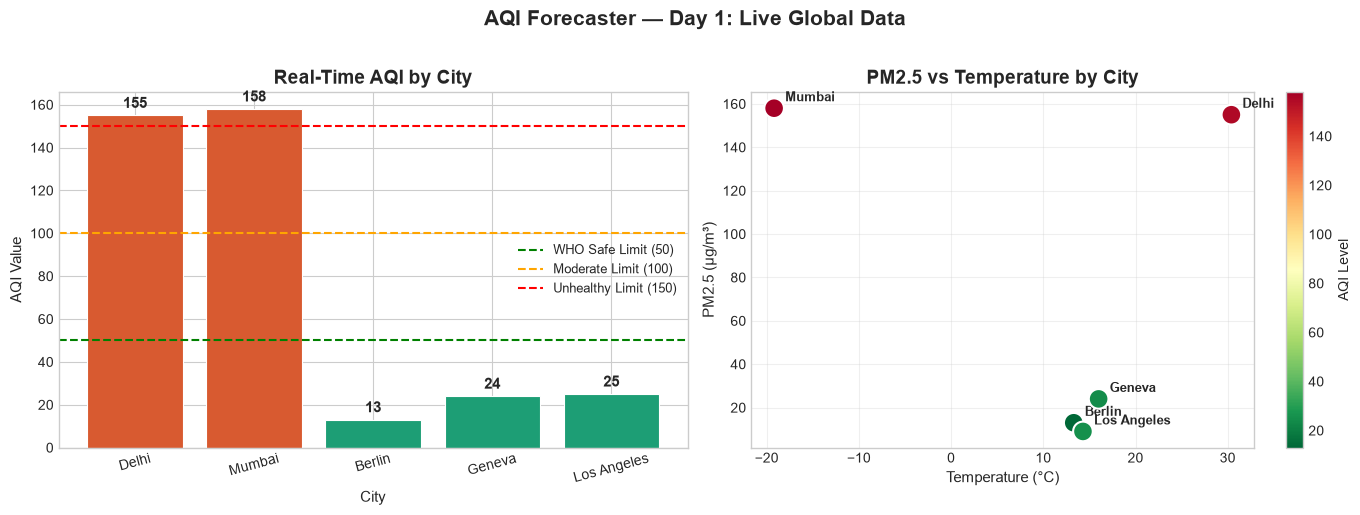


✓ Plot saved to: ../results/day1_visualization.png
✓ Live data fetched from 5 global cities
✓ Data saved to data/raw/waqi_realtime.csv
✓ First visualization created
✓ Delhi AQI:  155 — Unhealthy
✓ Berlin AQI: 13 — Good


In [10]:
# ============================================
# First Visualization 
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: AQI by City (Bar Chart) ---
colors = []
for aqi in df_raw['aqi']:
    if aqi <= 50:
        colors.append('#1D9E75')
    elif aqi <= 100:
        colors.append('#F0C419')
    elif aqi <= 150:
        colors.append('#F07F19')
    else:
        colors.append('#D85A30')

bars = axes[0].bar(df_raw['city'], df_raw['aqi'], color=colors,
                   edgecolor='white', linewidth=0.8)

axes[0].axhline(y=50,  color='green',  linestyle='--',
                linewidth=1.5, label='WHO Safe Limit (50)')
axes[0].axhline(y=100, color='orange', linestyle='--',
                linewidth=1.5, label='Moderate Limit (100)')
axes[0].axhline(y=150, color='red',    linestyle='--',
                linewidth=1.5, label='Unhealthy Limit (150)')

for bar, val in zip(bars, df_raw['aqi']):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 2,
                 str(val), ha='center', va='bottom',
                 fontweight='bold', fontsize=11)

axes[0].set_title('Real-Time AQI by City', fontsize=14, fontweight='bold')
axes[0].set_xlabel('City', fontsize=11)
axes[0].set_ylabel('AQI Value', fontsize=11)
axes[0].legend(fontsize=9)
axes[0].tick_params(axis='x', rotation=15)

# --- Plot 2: PM2.5 vs Temperature Scatter ---
sc = axes[1].scatter(df_raw['temperature'], df_raw['pm25'],
                     c=df_raw['aqi'], cmap='RdYlGn_r',
                     s=200, edgecolors='white', linewidth=1.5,
                     zorder=5)

for _, row in df_raw.iterrows():
    axes[1].annotate(row['city'],
                     (row['temperature'], row['pm25']),
                     textcoords='offset points',
                     xytext=(8, 5),
                     fontsize=9,
                     fontweight='bold')

plt.colorbar(sc, ax=axes[1], label='AQI Level')
axes[1].set_title('PM2.5 vs Temperature by City',
                  fontsize=14, fontweight='bold')
axes[1].set_xlabel('Temperature (°C)', fontsize=11)
axes[1].set_ylabel('PM2.5 (µg/m³)', fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.suptitle('AQI Forecaster — Day 1: Live Global Data',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

# Save plot
plot_path = '../results/day1_visualization.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✓ Plot saved to: {plot_path}")
print("=" * 40)
print(f"✓ Live data fetched from 5 global cities")
print(f"✓ Data saved to data/raw/waqi_realtime.csv")
print(f"✓ First visualization created")
print(f"✓ Delhi AQI:  {df_raw[df_raw['city']=='Delhi']['aqi'].values[0]} — Unhealthy")
print(f"✓ Berlin AQI: {df_raw[df_raw['city']=='Berlin']['aqi'].values[0]} — Good")
print("=" * 40)
